# Q1.1 - Faster R-CNN RPN Visualizations

This notebook runs the full training pipeline and generates all three visualizations:
1. **Objectness heatmaps** per FPN level
2. **Object proposal** overlays
3. **Anchor assignment** (positive/negative) overlays

Training is run **two times** with different hyperparameter configs so you can compare.

## 0. Sanity check - data and GPU

In [1]:
import os, glob, torch

# ---- GPU check ----
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# ---- Data check ----
imgs = glob.glob('data/img/*.jpg')
print(f"\nTotal images found: {len(imgs)}")
print("First few:", [os.path.basename(p) for p in imgs[:3]])

CUDA available: True
GPU: NVIDIA GeForce RTX 2080 Ti
VRAM: 11.3 GB

Total images found: 0
First few: []


In [4]:
import os
import sys

cwd = os.path.dirname(os.path.abspath("."))
print(cwd)

sys.path.append(cwd)


/home2/ameyk/cv/assignment-3-ameykaran/q1


## 1. Configure hyperparameter sweeps

Three configurations are run sequentially. The key parameters and their effects:

| Config | `rpn_post_nms_top_n_train` | `rpn_fg_iou_thresh` | `rpn_positive_fraction` | Notes |
|--------|--------------------------|---------------------|------------------------|-------|
| 1 | 2000 | 0.8 | 0.8 | Many proposals, strict IOU, heavily positive |
| 2 | 1000 | 0.7 | 0.5 | Moderate - standard defaults |

**What to look for across configs:**
- Config 1 → heatmaps develop *slowly* (high pos fraction forces the model to over-predict objectness)
- Config 3 → proposal boxes in Viz 2 will be much sparser and more selective
- Lower `fg_iou_thresh` (Config 3) → many more green anchors in Viz 3

In [7]:
# Hyperparameter sweep values
rpn_post_nms_top_n_train_vals = [2000, 1000]
rpn_fg_iou_thresh_vals        = [0.8,  0.7]
rpn_positive_fraction_vals    = [0.8,  0.5]

# Config file (controls dataset path, num_epochs, etc.)
CONFIG = '../config/st.yaml'

# Set this to True to do a quick 2-epoch sanity check before the full run
DRY_RUN = False

for i, (topn, iou, frac) in enumerate(
    zip(rpn_post_nms_top_n_train_vals, rpn_fg_iou_thresh_vals, rpn_positive_fraction_vals)
):
    name = f'topn{topn}_iou{iou}_frac{frac}'
    print(f'Config {i+1}: {name}')

Config 1: topn2000_iou0.8_frac0.8
Config 2: topn1000_iou0.7_frac0.5


## 2. (Optional) Quick sanity check - 2 epochs only

Run this cell to verify everything works before committing to the full training run.
It temporarily overrides `num_epochs` to 2 and only runs config 1.

In [8]:
DRY_RUN = True
if DRY_RUN:
    import yaml, types, argparse
    import train as train_module

    with open(CONFIG) as f:
        cfg = yaml.safe_load(f)
    cfg['train_params']['num_epochs'] = 1

    # Monkey-patch yaml.safe_load to return our modified config
    orig_load = yaml.safe_load
    yaml.safe_load = lambda *a, **kw: cfg

    args = argparse.Namespace(
        config_path=CONFIG,
        rpn_post_nms_top_n_train=rpn_post_nms_top_n_train_vals[1],
        rpn_fg_iou_thresh=rpn_fg_iou_thresh_vals[1],
        rpn_positive_fraction=rpn_positive_fraction_vals[1],
    )
    train_module.train(args)

    yaml.safe_load = orig_load  # restore
    print('\nDry run complete! Check outputs/ for PNG frames.')
else:
    print('DRY_RUN=False, skipping.')

{'dataset_params': {'root_dir': '../data', 'num_classes': 2}, 'model_params': {'im_channels': 3, 'aspect_ratios': [0.5, 1, 2], 'scales': [128, 256, 512], 'min_im_size': 600, 'max_im_size': 1000, 'backbone_out_channels': 512, 'fc_inner_dim': 1024, 'rpn_bg_threshold': 0.3, 'rpn_fg_threshold': 0.7, 'rpn_nms_threshold': 0.7, 'rpn_train_prenms_topk': 12000, 'rpn_test_prenms_topk': 6000, 'rpn_train_topk': 2000, 'rpn_test_topk': 300, 'rpn_batch_size': 256, 'rpn_pos_fraction': 0.5, 'roi_iou_threshold': 0.5, 'roi_low_bg_iou': 0.0, 'roi_pool_size': 7, 'roi_nms_threshold': 0.3, 'roi_topk_detections': 100, 'roi_score_threshold': 0.05, 'roi_batch_size': 128, 'roi_pos_fraction': 0.25}, 'train_params': {'task_name': 'st', 'seed': 1111, 'infer_seed': 1122, 'acc_steps': 1, 'num_epochs': 1, 'lr_steps': [12, 16], 'lr': 0.001, 'ckpt_name': 'faster_rcnn_st.pth'}}


100%|██████████| 90/90 [00:11<00:00,  7.52it/s]


Finished epoch 0
Validation Loss: 0.8277017038729456
✅ Saved BEST model at epoch 0 with val loss 0.8277
RPN Classification Loss : 0.1683 | RPN Localization Loss : 0.1090 | FRCNN Classification Loss : 0.2678 | FRCNN Localization Loss : 0.2975
Done Training...
Model loaded successfully


100%|██████████| 91/91 [00:15<00:00,  6.04it/s]


Final Test Loss: 0.8418
Test mAP: {'map': tensor(0.0771), 'map_50': tensor(0.2333), 'map_75': tensor(0.0291), 'map_small': tensor(0.0577), 'map_medium': tensor(0.1008), 'map_large': tensor(0.0639), 'mar_1': tensor(0.0272), 'mar_10': tensor(0.1334), 'mar_100': tensor(0.2848), 'mar_small': tensor(0.1996), 'mar_medium': tensor(0.3097), 'mar_large': tensor(0.3291), 'map_per_class': tensor(-1.), 'mar_100_per_class': tensor(-1.), 'classes': tensor(1, dtype=torch.int32)}

Dry run complete! Check outputs/ for PNG frames.


## 3. Full training - all three hyperparameter configs

After each epoch the validation pass fires, which:
- Saves objectness heatmap PNGs to `outputs/<name>/objectness/`
- Saves proposal overlay PNGs to `outputs/<name>/object_proposals/`
- Saves anchor assignment PNGs to `outputs/<name>/bb_assignments/`

In [4]:
import argparse
import importlib
import train as train_module

for topn, iou, frac in zip(
    rpn_post_nms_top_n_train_vals,
    rpn_fg_iou_thresh_vals,
    rpn_positive_fraction_vals,
):
    name = f'topn{topn}_iou{iou}_frac{frac}'
    print(f'\n{"="*60}')
    print(f'Starting config: {name}')
    print(f'{"="*60}')

    args = argparse.Namespace(
        config_path=CONFIG,
        rpn_post_nms_top_n_train=topn,
        rpn_fg_iou_thresh=iou,
        rpn_positive_fraction=frac,
    )
    train_module.train(args)

print('\nAll configs done!')


Starting config: topn2000_iou0.8_frac0.8
{'dataset_params': {'root_dir': 'data', 'num_classes': 2}, 'model_params': {'im_channels': 3, 'aspect_ratios': [0.5, 1, 2], 'scales': [128, 256, 512], 'min_im_size': 600, 'max_im_size': 1000, 'backbone_out_channels': 512, 'fc_inner_dim': 1024, 'rpn_bg_threshold': 0.3, 'rpn_fg_threshold': 0.7, 'rpn_nms_threshold': 0.7, 'rpn_train_prenms_topk': 12000, 'rpn_test_prenms_topk': 6000, 'rpn_train_topk': 2000, 'rpn_test_topk': 300, 'rpn_batch_size': 256, 'rpn_pos_fraction': 0.5, 'roi_iou_threshold': 0.5, 'roi_low_bg_iou': 0.0, 'roi_pool_size': 7, 'roi_nms_threshold': 0.3, 'roi_topk_detections': 100, 'roi_score_threshold': 0.05, 'roi_batch_size': 128, 'roi_pos_fraction': 0.25}, 'train_params': {'task_name': 'st', 'seed': 1111, 'infer_seed': 1122, 'acc_steps': 1, 'num_epochs': 20, 'lr_steps': [12, 16], 'lr': 0.001, 'ckpt_name': 'faster_rcnn_st.pth'}}


100%|██████████| 90/90 [00:08<00:00, 10.26it/s]


Finished epoch 0
Validation Loss: 0.8416911358634631
✅ Saved BEST model at epoch 0 with val loss 0.8417
RPN Classification Loss : 0.1828 | RPN Localization Loss : 0.1188 | FRCNN Classification Loss : 0.2657 | FRCNN Localization Loss : 0.3555


100%|██████████| 90/90 [00:08<00:00, 10.51it/s]


Finished epoch 1
Validation Loss: 0.7667725294828415
✅ Saved BEST model at epoch 1 with val loss 0.7668
RPN Classification Loss : 0.0786 | RPN Localization Loss : 0.0984 | FRCNN Classification Loss : 0.2382 | FRCNN Localization Loss : 0.3733


100%|██████████| 90/90 [00:08<00:00, 10.66it/s]


... (75 outputs left out)

100%|██████████| 90/90 [00:08<00:00, 10.35it/s]


Finished epoch 19
Validation Loss: 0.7976088734136687
RPN Classification Loss : 0.0122 | RPN Localization Loss : 0.0376 | FRCNN Classification Loss : 0.1323 | FRCNN Localization Loss : 0.2189
Done Training...
Model loaded successfully


100%|██████████| 91/91 [00:08<00:00, 10.68it/s]


Final Test Loss: 0.7040
Test mAP: {'map': tensor(0.2772), 'map_50': tensor(0.5677), 'map_75': tensor(0.2404), 'map_small': tensor(0.1444), 'map_medium': tensor(0.3149), 'map_large': tensor(0.3441), 'mar_1': tensor(0.0571), 'mar_10': tensor(0.2811), 'mar_100': tensor(0.4222), 'mar_small': tensor(0.2960), 'mar_medium': tensor(0.4582), 'mar_large': tensor(0.4896), 'map_per_class': tensor(-1.), 'mar_100_per_class': tensor(-1.), 'classes': tensor(1, dtype=torch.int32)}

All configs done!


## 4. Compile PNG frames into MP4 videos

In [40]:
import subprocess
result = subprocess.run(
    ['python', 'make_videos.py', '--fps', '2'],
    capture_output=True, text=True
)
print(result.stdout)
if result.stderr:
    print('STDERR:', result.stderr)


=== topn1000_iou0.7_frac0.5 ===
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img0_level0.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img0_level1.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img0_level2.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img0_level3.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img0_level4.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img1_level0.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img1_level1.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img1_level2.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img1_level3.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img1_level4.gif  (20 frames @ 2 fps)
  Saved → outputs/topn1000_iou0.7_frac0.5/objectness_img2_level0.gi

## 5. Preview outputs

### 5a. Objectness heatmaps - compare last epoch across configs

In [6]:
%matplotlib inline

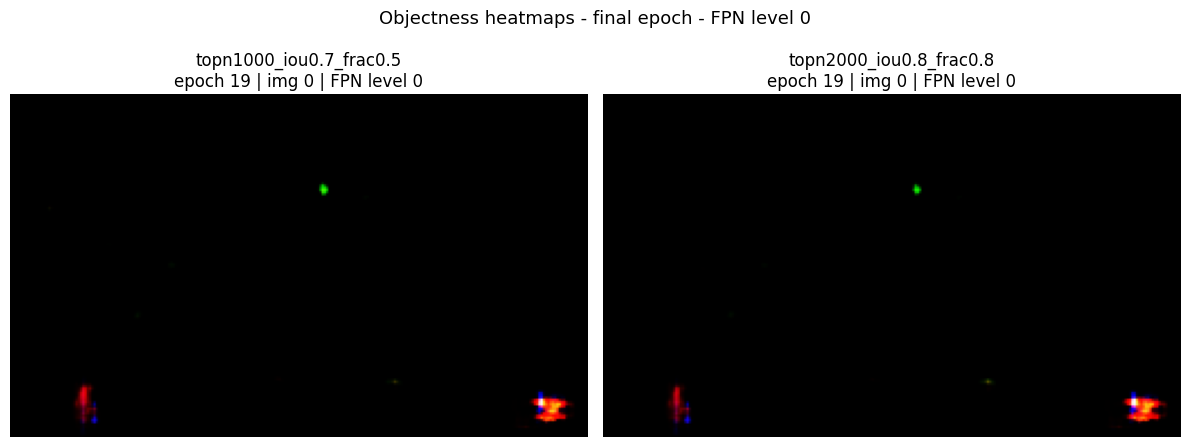

In [23]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import glob, os, re

configs = sorted(
    d for d in os.listdir('outputs')
    if os.path.isdir(f'outputs/{d}') and d != 'images'
)

# Show last epoch, image 0, level 0 for each config side by side
fig, axes = plt.subplots(1, len(configs), figsize=(6 * len(configs), 5))
if len(configs) == 1:
    axes = [axes]

for ax, cfg in zip(axes, configs):
    frames = sorted(glob.glob(f'outputs/{cfg}/objectness/epoch*_img7_level0.png'))
    if not frames:
        ax.set_title(f'{cfg}\n(no frames yet)')
        ax.axis('off')
        continue
    img = mpimg.imread(frames[-1])  # last epoch
    epoch = re.search(r'epoch(\d+)', frames[-1]).group(1)
    ax.imshow(img)
    ax.set_title(f'{cfg}\nepoch {int(epoch)} | img 0 | FPN level 0')
    ax.axis('off')

plt.suptitle('Objectness heatmaps - final epoch - FPN level 0', fontsize=13)
plt.tight_layout()
plt.show()

### 5b. All FPN levels - single config, last epoch

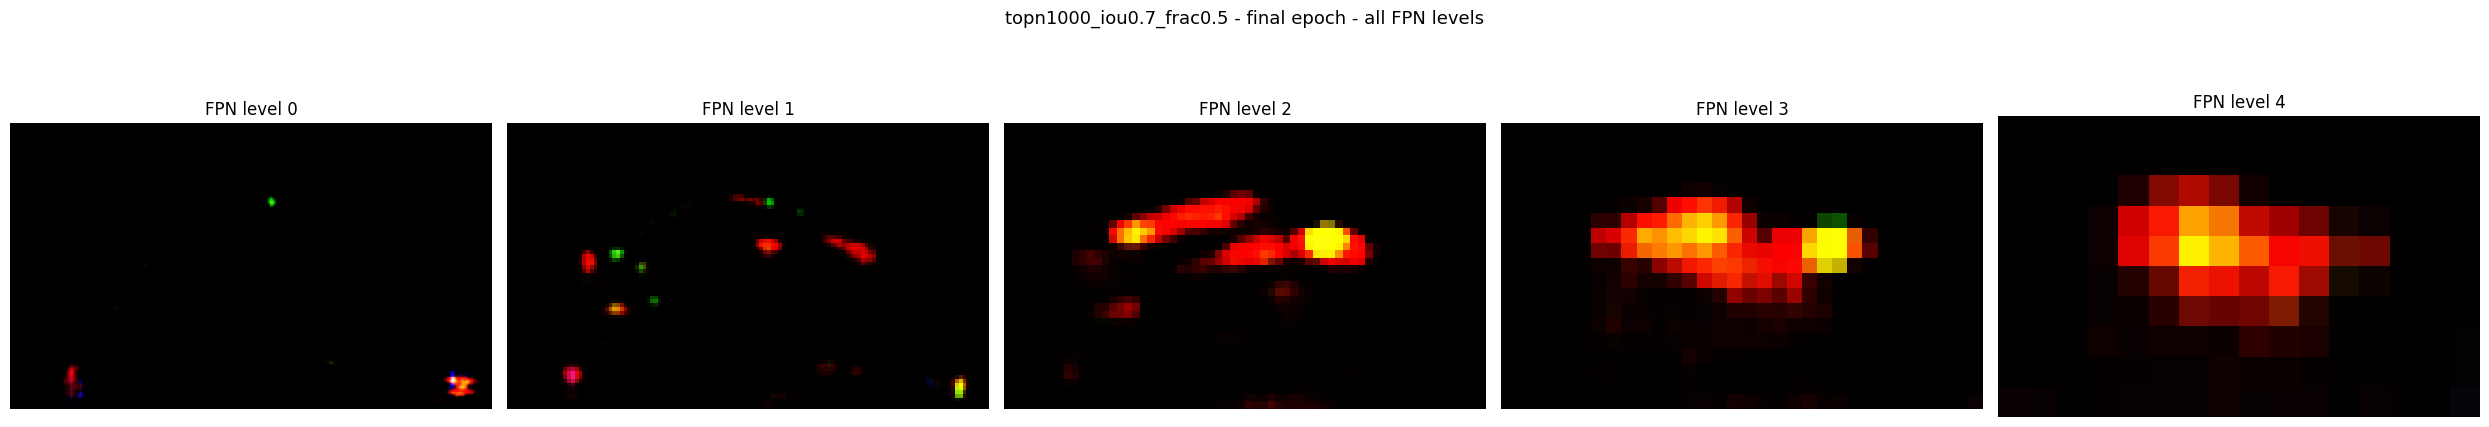

In [24]:
SHOW_CONFIG = configs[0]  # change to configs[1] or configs[2] to see others

levels = sorted(set(
    int(re.search(r'level(\d+)', f).group(1))
    for f in glob.glob(f'outputs/{SHOW_CONFIG}/objectness/epoch*_img7_level*.png')
))

frames_per_level = {}
for lvl in levels:
    fs = sorted(glob.glob(f'outputs/{SHOW_CONFIG}/objectness/epoch*_img7_level{lvl}.png'))
    if fs:
        frames_per_level[lvl] = fs

fig, axes = plt.subplots(1, len(frames_per_level), figsize=(5 * len(frames_per_level), 5))
if len(frames_per_level) == 1:
    axes = [axes]

for ax, (lvl, fs) in zip(axes, frames_per_level.items()):
    img = mpimg.imread(fs[-1])
    ax.imshow(img)
    ax.set_title(f'FPN level {lvl}')
    ax.axis('off')

plt.suptitle(f'{SHOW_CONFIG} - final epoch - all FPN levels', fontsize=13)
plt.tight_layout()
plt.show()

### 5c. Object proposals - compare last epoch across configs

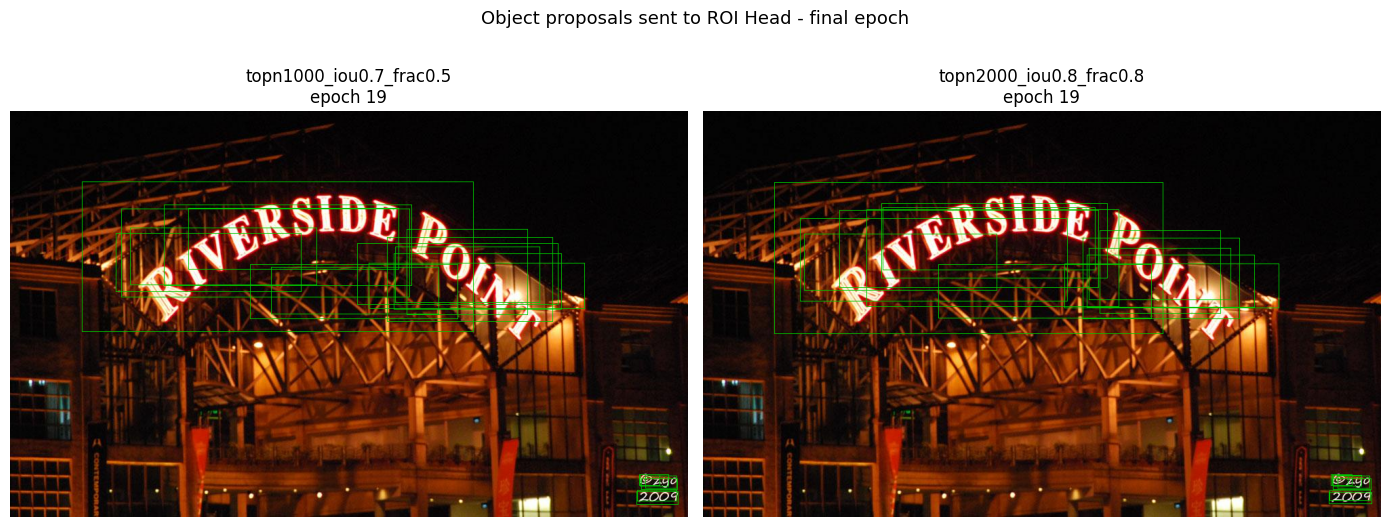

In [31]:
fig, axes = plt.subplots(1, len(configs), figsize=(7 * len(configs), 6))
if len(configs) == 1:
    axes = [axes]

for ax, cfg in zip(axes, configs):
    frames = sorted(glob.glob(f'outputs/{cfg}/object_proposals/epoch*_img7.png'))
    if not frames:
        ax.set_title(f'{cfg}\n(no frames)')
        ax.axis('off')
        continue
    img = mpimg.imread(frames[-1])
    epoch = re.search(r'epoch(\d+)', frames[-1]).group(1)
    ax.imshow(img)
    ax.set_title(f'{cfg}\nepoch {int(epoch)}')
    ax.axis('off')

plt.suptitle('Object proposals sent to ROI Head - final epoch', fontsize=13)
plt.tight_layout()
plt.show()

### 5d. Anchor assignments - compare configs

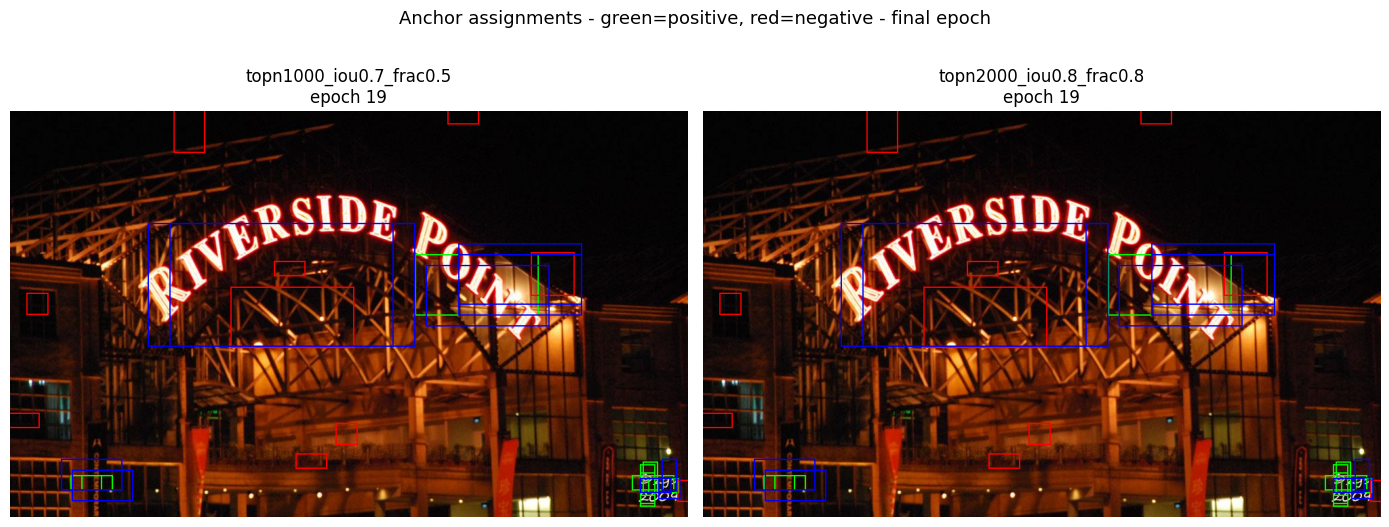

In [32]:
fig, axes = plt.subplots(1, len(configs), figsize=(7 * len(configs), 6))
if len(configs) == 1:
    axes = [axes]

for ax, cfg in zip(axes, configs):
    frames = sorted(glob.glob(f'outputs/{cfg}/bb_assignments/epoch*_img7.png'))
    if not frames:
        ax.set_title(f'{cfg}\n(no frames)')
        ax.axis('off')
        continue
    img = mpimg.imread(frames[-1])
    epoch = re.search(r'epoch(\d+)', frames[-1]).group(1)
    ax.imshow(img)
    ax.set_title(f'{cfg}\nepoch {int(epoch)}')
    ax.axis('off')

plt.suptitle('Anchor assignments - green=positive, red=negative - final epoch', fontsize=13)
plt.tight_layout()
plt.show()

### 5e. Play a video inline (objectness, any config)

In [33]:
from IPython.display import Video

SHOW_CONFIG = configs[0]   # pick config
IMG_IDX     = 0            # pick image index
LEVEL       = 0            # pick FPN level

vid = f'outputs/{SHOW_CONFIG}/objectness_img{IMG_IDX}_level{LEVEL}.mp4'
if os.path.exists(vid):
    Video(vid, embed=True, width=640)
else:
    print('Video not found. Run cell 4 (make_videos.py) first.')

In [34]:
# Object proposals video
vid = f'outputs/{SHOW_CONFIG}/object_proposals_img{IMG_IDX}.mp4'
if os.path.exists(vid):
    Video(vid, embed=True, width=640)
else:
    print('Video not found. Run cell 4 (make_videos.py) first.')

In [35]:
# Anchor assignments video
vid = f'outputs/{SHOW_CONFIG}/bb_assignments_img{IMG_IDX}.mp4'
if os.path.exists(vid):
    Video(vid, embed=True, width=640)
else:
    print('Video not found. Run cell 4 (make_videos.py) first.')

### 5f. Scrub through frames manually (animation strip)

In [38]:
from ipywidgets import interact, IntSlider

SHOW_CONFIG = configs[0]
VIZ = 'objectness'   # 'objectness' | 'object_proposals' | 'bb_assignments'
IMG_IDX = 7
LEVEL = 0

if VIZ == 'objectness':
    frames = sorted(glob.glob(f'outputs/{SHOW_CONFIG}/objectness/epoch*_img{IMG_IDX}_level{LEVEL}.png'))
else:
    frames = sorted(glob.glob(f'outputs/{SHOW_CONFIG}/{VIZ}/epoch*_img{IMG_IDX}.png'))

if not frames:
    print('No frames found yet - run training first.')
else:
    def show(epoch_frame=0):
        fig, ax = plt.subplots(figsize=(8, 6))
        img = mpimg.imread(frames[epoch_frame])
        epoch = re.search(r'epoch(\d+)', frames[epoch_frame]).group(1)
        ax.imshow(img)
        ax.set_title(f'{VIZ} | epoch {int(epoch)}')
        ax.axis('off')
        plt.show()

    interact(show, epoch_frame=IntSlider(min=0, max=len(frames)-1, step=1, description='Epoch'))

interactive(children=(IntSlider(value=0, description='Epoch', max=19), Output()), _dom_classes=('widget-intera…